# Phase 5 walkthrough — real AESO data (2024–2025)

This notebook reads the **cached** AESO responses in `data/raw/` and the Phase 5 reports, so it runs without an
API key. To (re)pull the data: set `AESO_API_KEY` and run `python -m src.run --phases 5` (cached chunks are skipped).
Endpoint shapes and quirks: `docs/aeso_api_probe.md`.

In [1]:
import os, sys, glob, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
from src import aeso_api as A
from src.config import load_config
cfg = load_config(); a = cfg["aeso"]
read = lambda ep: pd.concat(pd.read_parquet(f) for f in sorted(glob.glob(f"data/raw/{ep}/*.parquet")))
pool, ail = read("poolprice").drop_duplicates("ts_utc"), read("ail").drop_duplicates("ts_utc")
summary = json.load(open("reports/phase5_summary.json"))
print(len(pool), "pool-price hours,", len(ail), "AIL hours")

17544 pool-price hours, 17544 AIL hours


## 1. Completeness on the UTC key

In [2]:
pd.DataFrame({"pool price": A.completeness(pool.ts_utc, a["start"], a["end"], a["tz"]),
              "AIL": A.completeness(ail.ts_utc, a["start"], a["end"], a["tz"])}).T

,expected_hours,present_hours,missing_hours,first_missing,duplicate_rows
pool price,17544,17544,0,[],0
AIL,17544,17544,0,[],0


## 2. Why UTC is the key: the 2025-11-02 fall-back day
Local (MPT) 01:00 occurs twice; the UTC timestamps stay unique. Since 2026-11-01 Alberta is on UTC−6 year-round
(tz database 2026e), so the 2026 fall-back day has only 24 hours.

In [3]:
day = pool[(pool.ts_utc >= "2025-11-02 06:00Z") & (pool.ts_utc < "2025-11-02 11:00Z")]
display(day[["ts_utc", "ts_mpt", "pool_price"]])
print({d: len(A.expected_hours(d, d, a["tz"])) for d in ("2025-11-02", "2026-03-08", "2026-11-01")})

,ts_utc,ts_mpt,pool_price
7319,2025-11-02 06:00:00+00:00,2025-11-02 00:00,0.00
7320,2025-11-02 07:00:00+00:00,2025-11-02 01:00,0.00
7321,2025-11-02 08:00:00+00:00,2025-11-02 01:00,0.00
7322,2025-11-02 09:00:00+00:00,2025-11-02 02:00,0.00
7323,2025-11-02 10:00:00+00:00,2025-11-02 03:00,1.56


{'2025-11-02': 25, '2026-03-08': 23, '2026-11-01': 24}


## 3. Wind/solar coverage

fleet: {'WIND': 50, 'SOLAR': 49} {'WIND': 5684.0, 'SOLAR': 1892.0} | with data: 97
missing from fuel snapshot but producing (GWh): {'AWE1': 9.8, 'AWE2': 8.7, 'IRR1': 14.6, 'MCS1': 13.2, 'SEL1': 2.3} = 0.14% of fleet energy


,asset_ID,fuel,capability_mw,first
0,ACD1,SOLAR,140.0,2024-11-22 18:00:00+00:00
1,BPW1,WIND,466.0,2024-08-28 22:00:00+00:00
2,CLD1,SOLAR,9.0,2024-10-15 16:00:00+00:00
3,FRM1,WIND,266.0,2024-10-23 16:00:00+00:00
4,GLE1,SOLAR,14.0,2025-04-10 18:00:00+00:00
5,HAL2,WIND,122.0,2024-10-24 23:00:00+00:00
6,KKP1,SOLAR,7.0,2024-02-14 17:00:00+00:00
7,TLE1,SOLAR,24.0,2025-11-06 17:00:00+00:00
8,WIN1,WIND,136.0,2024-12-04 00:00:00+00:00
9,WIR1,WIND,192.0,2024-12-18 21:00:00+00:00


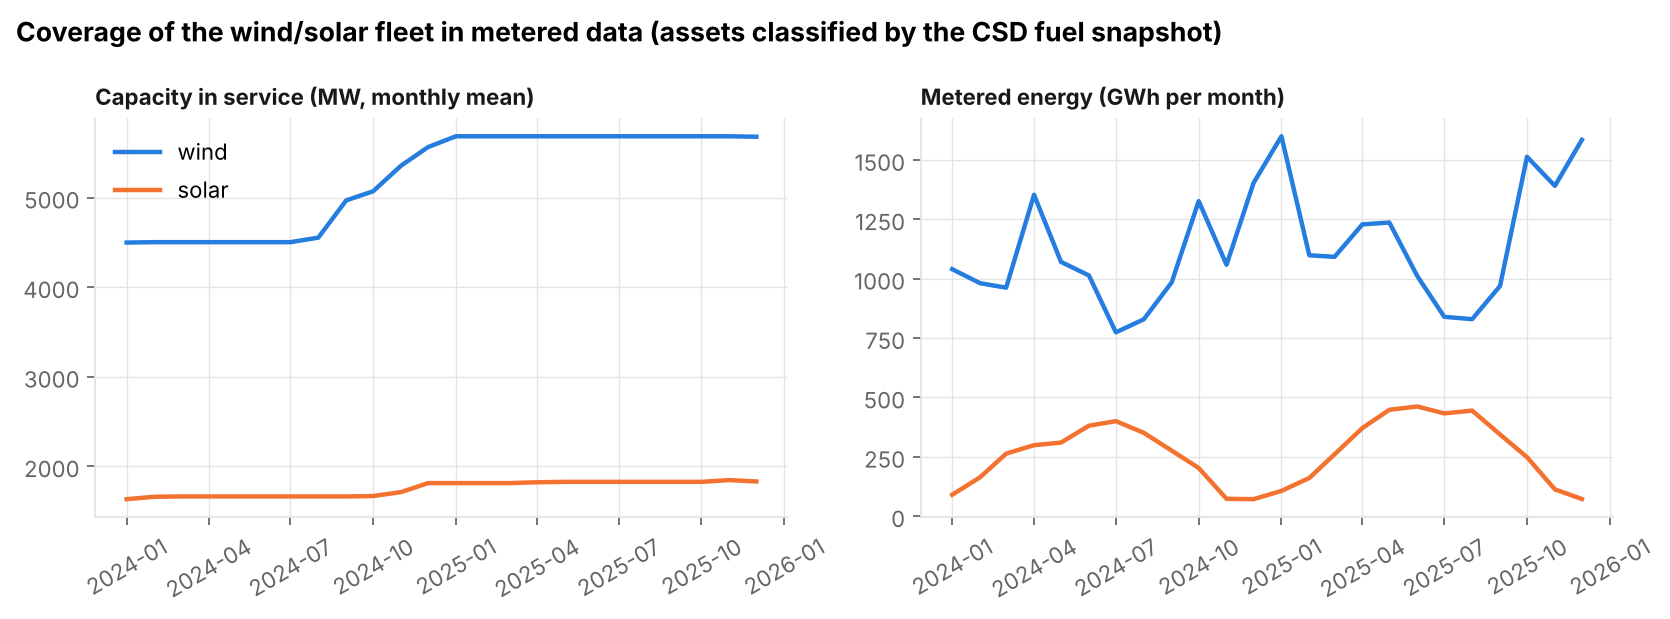

In [4]:
c = summary["coverage"]
print("fleet:", c["fleet_assets"], c["fleet_capability_mw"], "| with data:", c["fleet_assets_with_data"])
print("missing from fuel snapshot but producing (GWh):", c["candidates_with_output"],
      f"= {c['candidates_energy_share_of_fleet']:.2%} of fleet energy")
display(pd.DataFrame(c["commissioned_during_period"]))
display(Image("reports/figures/p5_coverage.png", width=900))

## 4. Real vs synthetic shapes

,mean,std,p05,p95,lag1_autocorr,lag24_autocorr,share_below_5pct_of_max,peak_hour
series,,,,,,,,
load MW · real AIL,10214.175,817.838,8912.150,11643.850,0.980,0.942,0.000,17
load MW · synthetic,9798.600,908.175,8367.956,11389.656,0.964,0.909,0.000,18
wind CF · real fleet,0.298,0.195,0.024,0.630,0.982,0.325,0.088,23
wind CF · synthetic,0.394,0.330,0.011,0.963,0.963,0.449,0.168,13
solar CF · real fleet,0.207,0.286,0.000,0.810,0.944,0.882,0.551,13
solar CF · synthetic,0.118,0.196,0.000,0.592,0.935,0.721,0.639,13


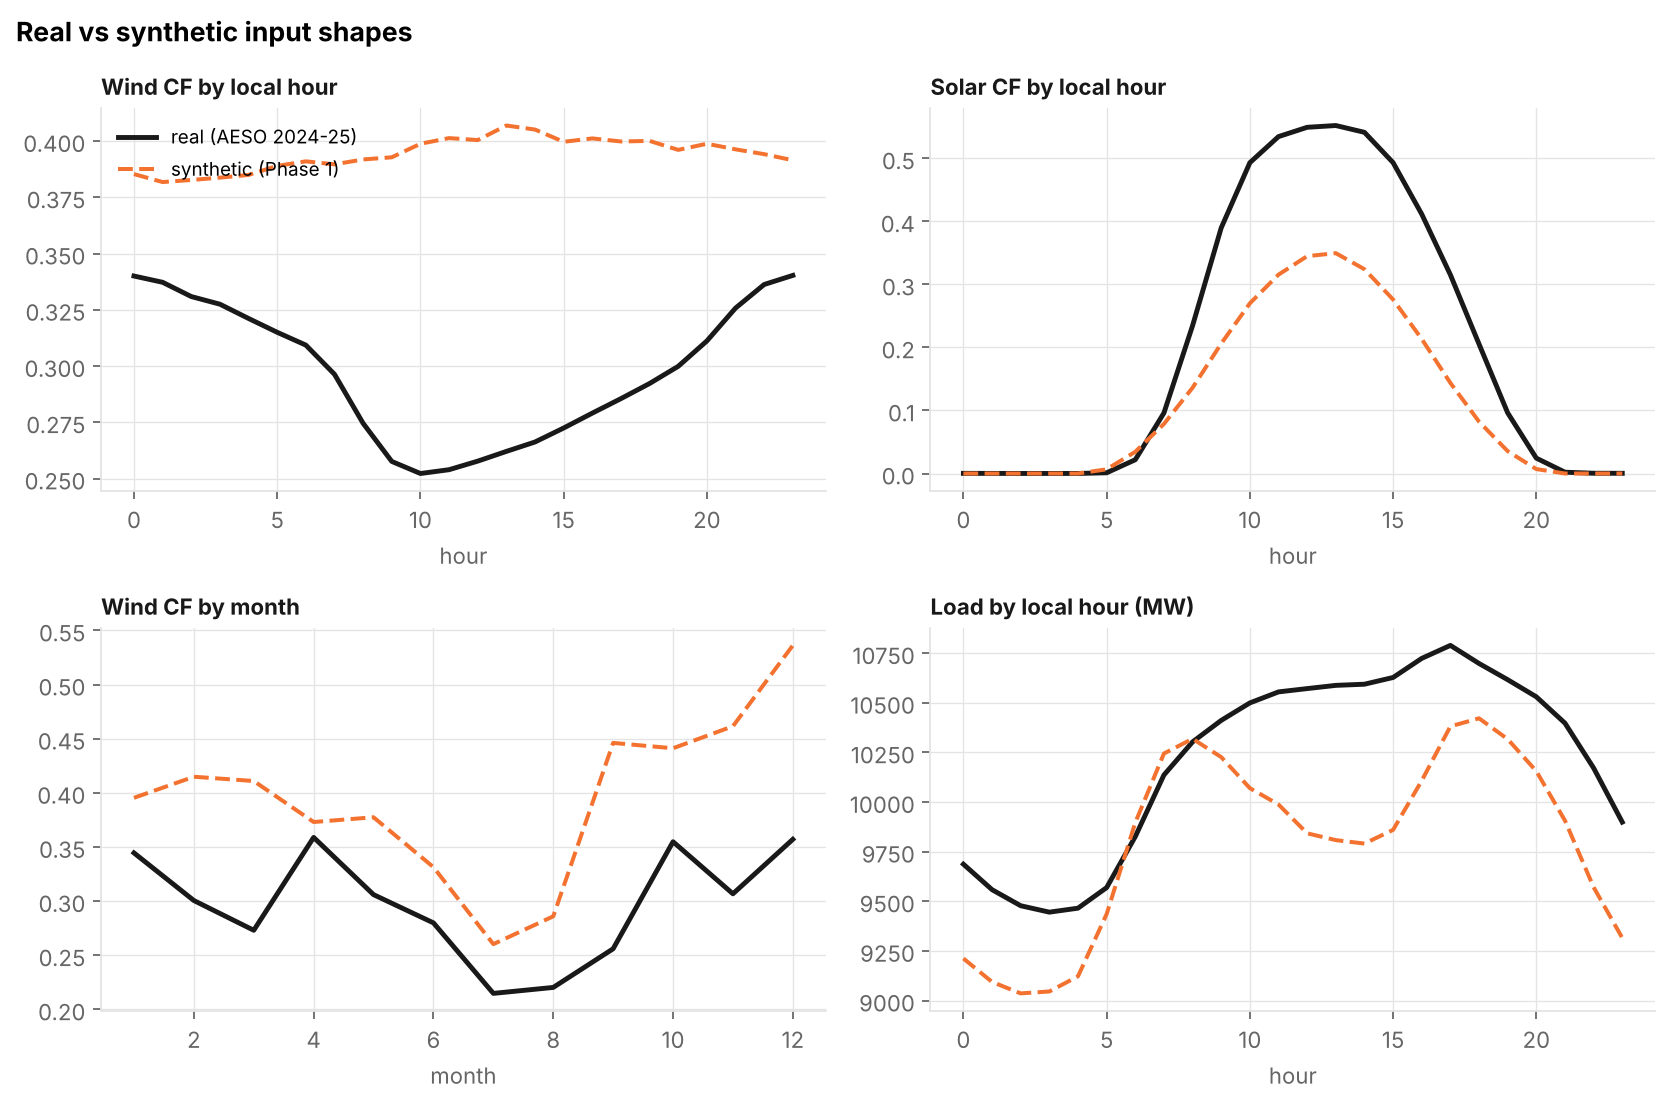

In [5]:
display(pd.read_csv("reports/tables/phase5_shapes.csv", index_col=0).round(3))
display(Image("reports/figures/p5_shapes.png", width=900))

## 5. Price calibration (copper plate): fitted on 2024, tested on 2025

best: {'gas_mult': 0.7, 'cogen_must_run': 0.0, 'dist_fit': 20.608754736842112, 'dist_test': 14.71365473684211}


mean     std    P10    P50     P90  \
series                   period                                                
real pool price          2024 (fit)      62.78  124.20   8.27  30.56  112.22   
                         2025 (test)     43.68  104.07   1.72  22.91   63.95   
                         2024-2025       53.24  114.98   4.75  26.74   84.50   
model · base costs       2024 (fit)      46.45    5.05  42.00  45.00   55.00   
                         2025 (test)     47.09    5.34  42.00  45.00   55.00   
                         2024-2025       46.77    5.21  42.00  45.00   55.00   
model · calibrated       2024 (fit)      33.26    5.20  29.40  31.50   45.50   
                         2025 (test)     33.79    5.55  29.40  31.50   45.50   
                         2024-2025       33.52    5.39  29.40  31.50   45.50   
model · synthetic inputs synthetic 2 yr  44.51    6.78  40.00  45.00   50.00   

                                            P99     max  share_le_1  \
series                   period                                       
real pool price          2024 (fit)      771.93  999.99        0.05   
                         2025 (test)     705.87  999.99        0.09   
                         2024-2025       746.39  999.99        0.07   
model · base costs       2024 (fit)       65.00   65.00        0.00   
                         2025 (test)      65.00  120.00        0.00   
                         2024-2025        65.00  120.00        0.00   
model · calibrated       2024 (fit)       45.50   55.00        0.00   
                         2025 (test)      55.00   84.00        0.00   
                         2024-2025        55.00   84.00        0.00   
model · synthetic inputs synthetic 2 yr   65.00  120.00        0.00   

                                         share_ge_100  share_ge_500  \
series                   period                                       
real pool price          2024 (fit)              0.11          0.02   
                         2025 (test)             0.05          0.02   
                         2024-2025               0.08          0.02   
model · base costs       2024 (fit)              0.00          0.00   
                         2025 (test)             0.00          0.00   
                         2024-2025               0.00          0.00   
model · calibrated       2024 (fit)              0.00          0.00   
                         2025 (test)             0.00          0.00   
                         2024-2025               0.00          0.00   
model · synthetic inputs synthetic 2 yr          0.00          0.00   

                                         share_ge_999  
series                   period                        
real pool price          2024 (fit)               0.0  
                         2025 (test)              0.0  
                         2024-2025                0.0  
model · base costs       2024 (fit)               0.0  
                         2025 (test)              0.0  
                         2024-2025                0.0  
model · calibrated       2024 (fit)               0.0  
                         2025 (test)              0.0  
                         2024-2025                0.0  
model · synthetic inputs synthetic 2 yr           0.0

,pearson_all,spearman_all,spearman_test_2025,mae_test_2025,median_abs_err_test_2025,quantile_distance_test_2025
base,0.40,0.66,0.7,40.05,25.32,23.55
calibrated,0.39,0.66,0.7,31.98,14.10,14.71


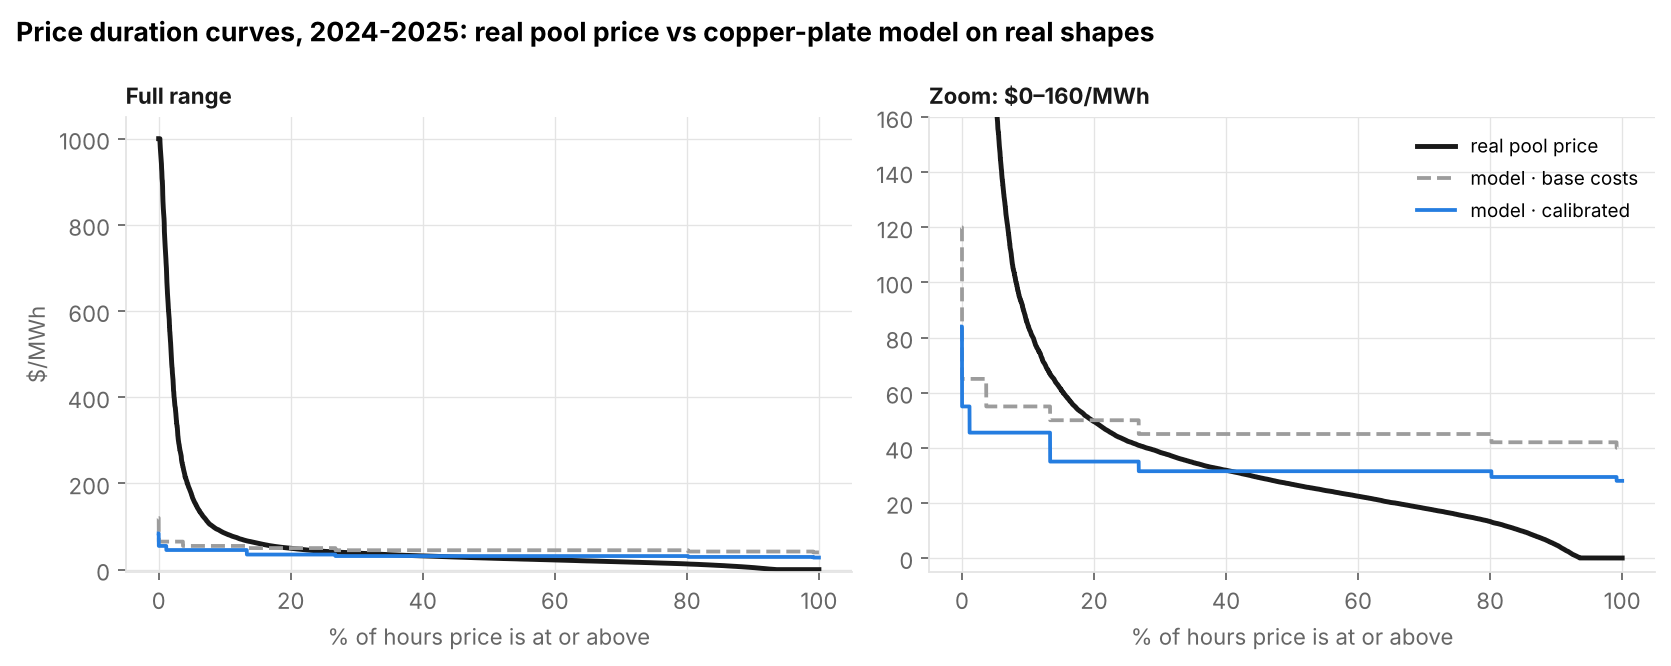

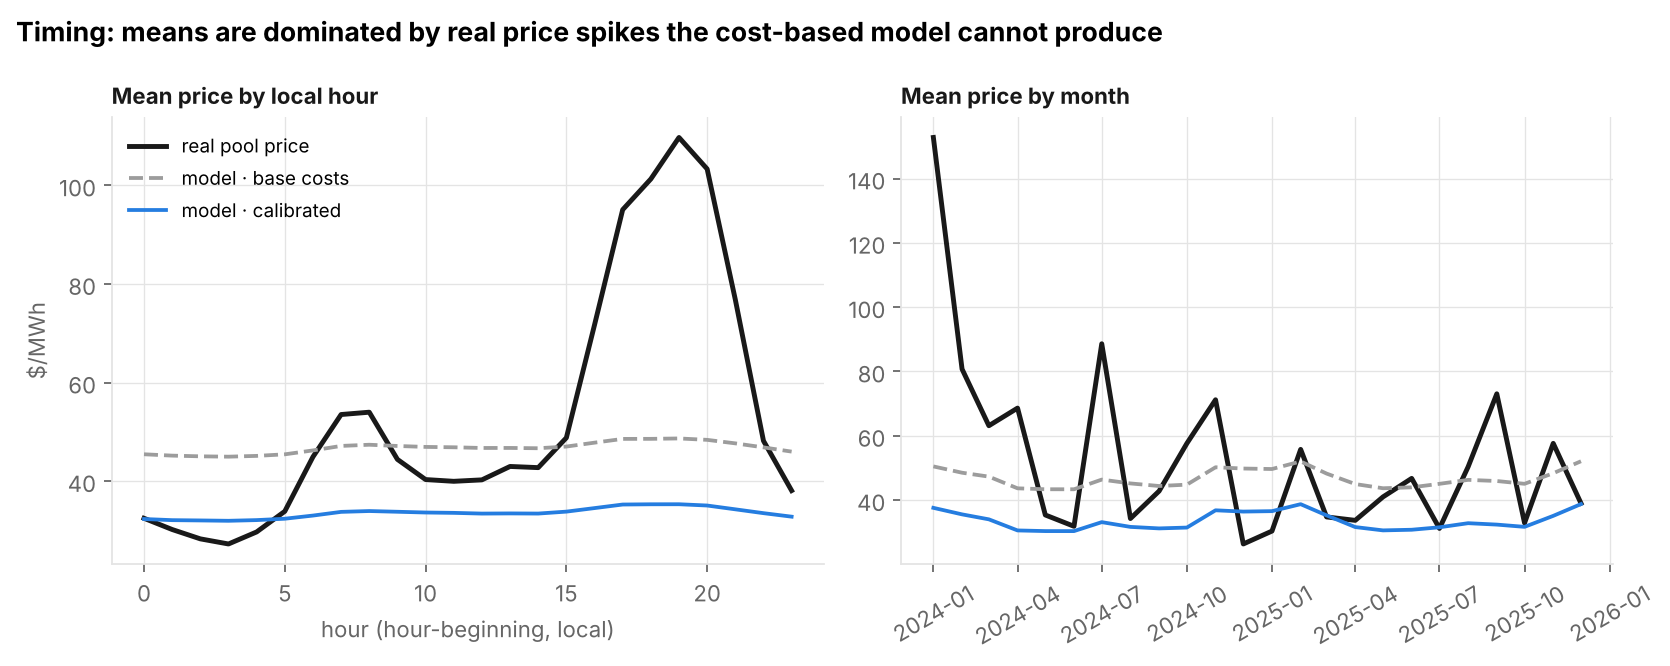

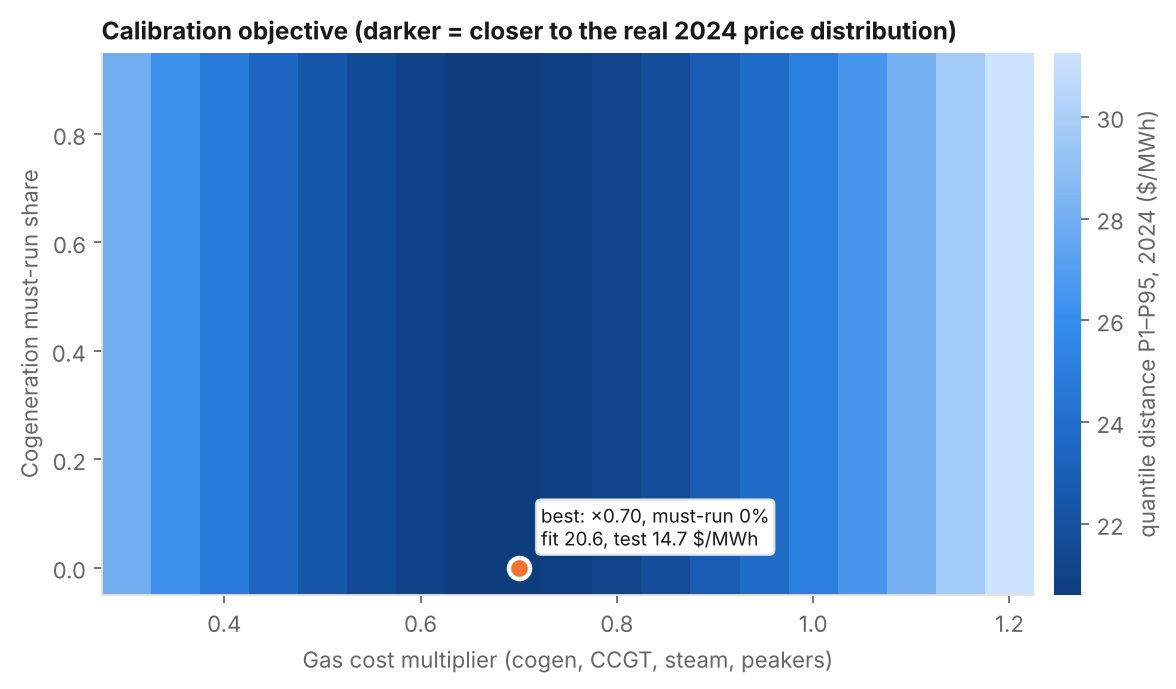

In [6]:
print("best:", summary["calibration"]["best"])
display(pd.read_csv("reports/tables/phase5_price_stats.csv", index_col=[0, 1]).round(2))
display(pd.DataFrame(summary["timing"]).T.round(2))
display(Image("reports/figures/p5_price_duration.png", width=900))
display(Image("reports/figures/p5_price_profiles.png", width=900))
display(Image("reports/figures/p5_calibration_surface.png", width=700))

## 6. Congestion with real shapes vs synthetic

,synthetic inputs (Phase 1),real shapes · base costs,real shapes · calibrated
SOUTH-CAL,22.1%,1.2%,1.2%
SOUTH-RD,0.0%,0.0%,0.0%
CAL-RD,0.0%,0.0%,0.0%
RD-EDM,0.0%,0.0%,0.0%
CAL-EDM,0.0%,0.0%,0.0%
EDM-NORTH-1,1.5%,1.5%,1.5%
EDM-NORTH-2,1.5%,1.5%,1.5%
BC-CAL,3.4%,5.3%,0.0%


{'real shapes · base costs': '7.9%', 'real shapes · calibrated': '2.7%', 'synthetic inputs (Phase 1)': '27.0%'}


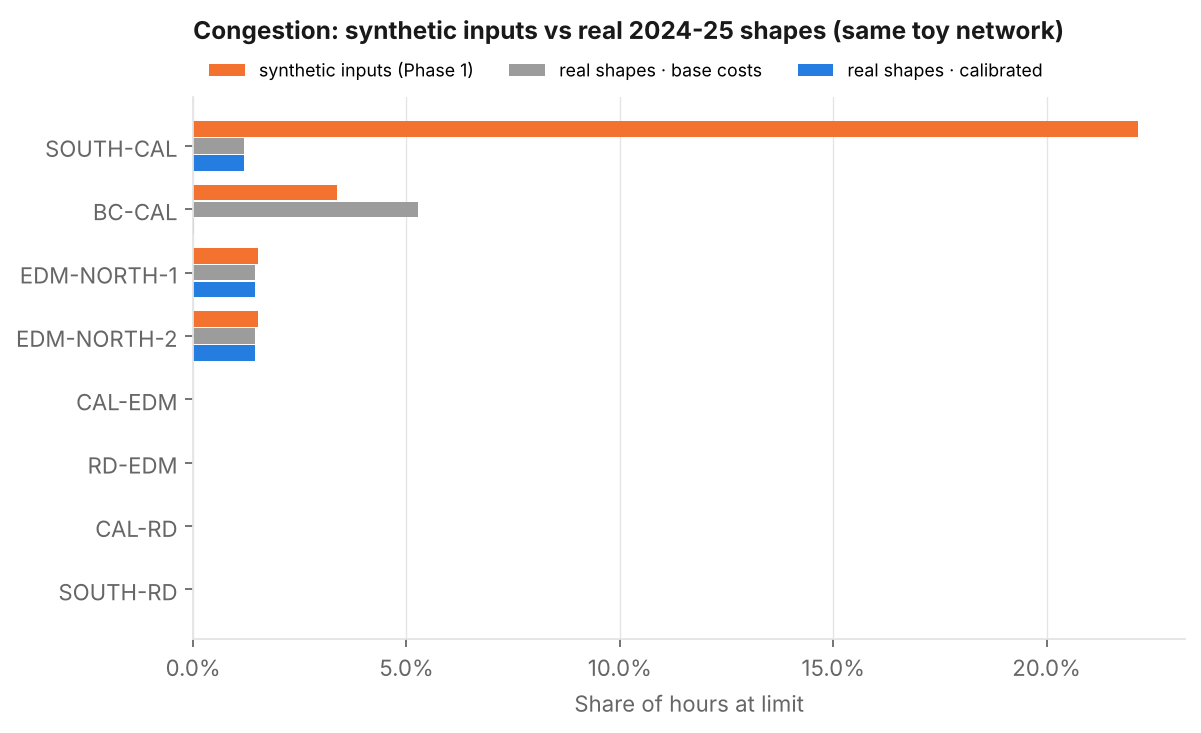

In [7]:
display(pd.read_csv("reports/tables/phase5_congestion.csv", index_col=0).style.format("{:.1%}"))
print({k: f"{v:.1%}" for k, v in summary["any_binding"].items()})
display(Image("reports/figures/p5_congestion.png", width=760))

## 7. The observed series in SQL

In [8]:
from sqlalchemy import inspect, text
from src import db
eng = db.get_engine(cfg)
if inspect(eng).has_table("aeso_hourly"):
    with eng.connect() as conn:
        display(pd.read_sql(text("SELECT COUNT(*) AS hours, AVG(pool_price) AS mean_price, AVG(ail_mw) AS mean_ail, "
                                 "AVG(wind_cf) AS mean_wind_cf, AVG(solar_cf) AS mean_solar_cf FROM aeso_hourly"), conn))
else:
    print("database has no aeso_hourly table yet (run phase 4, then phase 5)")

,hours,mean_price,mean_ail,mean_wind_cf,mean_solar_cf
0,17544,53.242042,10214.175388,0.297693,0.206786
